# PaySim : analyse exploratoire guidée

**Lot 4.0, étape 1.** Ce notebook lit le CSV PaySim brut depuis la racine du dépôt. Il ne modifie pas les données et n'entraîne aucun modèle. `isFraud` est consulté uniquement pour l'analyse hors ligne. Les autres labels ne sont pas des variables prédictives.

Les deux premières figures montrent le déséquilibre des classes et l'étendue des montants. Les conclusions sur les montants selon le label, les types, le temps et les soldes attendent la discussion avec l'utilisateur.


In [1]:
from pathlib import Path
from hashlib import sha256
from html import escape
import math
import polars as pl

CSV = Path("data/raw/PS_20174392719_1491204439457_log.csv")
FIGURES = Path("docs/figures")
EXPECTED_SHA256 = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
if not CSV.is_file():
    raise FileNotFoundError(f"CSV absent : {CSV}. Voir README.md pour le téléchargement.")
with CSV.open("rb") as source:
    digest = sha256()
    for block in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(block)
assert digest.hexdigest() == EXPECTED_SHA256, "Empreinte du CSV différente de l'audit"

frame = pl.scan_csv(CSV).select("amount", "isFraud")
summary = frame.select(
    pl.len().alias("total"),
    (pl.col("isFraud") == 0).sum().alias("normal"),
    (pl.col("isFraud") == 1).sum().alias("fraud"),
    (~pl.col("isFraud").is_in([0, 1])).sum().alias("other_label"),
    (pl.col("amount") == 0).sum().alias("zeros"),
    (pl.col("amount") < 0).sum().alias("negatives"),
    pl.col("amount").min().alias("minimum"),
    pl.col("amount").max().alias("maximum"),
    pl.col("amount").median().alias("median"),
    pl.col("amount").quantile(0.90).alias("p90"),
    pl.col("amount").quantile(0.99).alias("p99"),
).collect().row(0, named=True)
assert summary["total"] == 6_362_620
assert summary["normal"] + summary["fraud"] == summary["total"]
assert summary["other_label"] == 0 and summary["negatives"] == 0

# Tranches [10**e, 10**(e+1)) pour les montants strictement positifs.
bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns(pl.col("amount").log10().floor().cast(pl.Int32).alias("exponent"))
    .group_by("exponent").agg(pl.len().alias("count"))
    .sort("exponent").collect()
)
assert sum(bins["count"].to_list()) + summary["zeros"] == summary["total"]
assert bins["exponent"].to_list() == list(range(-2, 8))
print({key: summary[key] for key in ("total", "normal", "fraud", "zeros", "minimum", "maximum", "median", "p90", "p99")})
print(bins)


In [2]:
def svg_text(x, y, value, *, size=16, fill="#183047", anchor="start", weight="normal"):
    return (f'<text x="{x}" y="{y}" font-family="Arial, sans-serif" '
            f'font-size="{size}" fill="{fill}" text-anchor="{anchor}" '
            f'font-weight="{weight}">{escape(str(value))}</text>')


def show_svg(svg):
    try:
        from IPython.display import SVG, display
    except ModuleNotFoundError:
        return
    display(SVG(svg))


def save_svg(name, svg):
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / name
    path.write_text(svg, encoding="utf-8")
    return svg


def format_int(value):
    return f"{value:,}".replace(",", " ")


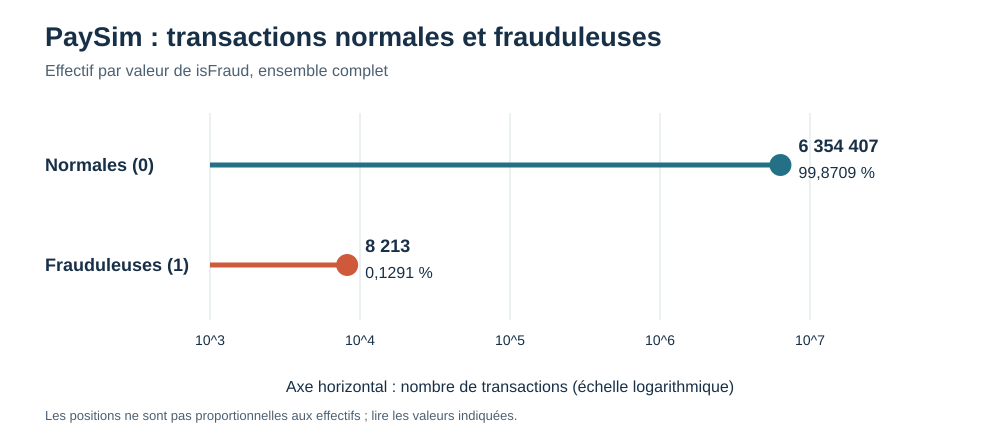

In [3]:
width, height = 1000, 440
left, right = 210, 810
x = lambda value: left + (math.log10(value) - 3) / 4 * (right - left)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(45, 46, "PaySim : transactions normales et frauduleuses", size=27, weight="bold"),
         svg_text(45, 76, "Effectif par valeur de isFraud, ensemble complet", size=16, fill="#4b6072")]
for power in range(3, 8):
    xpos = x(10 ** power)
    parts += [f'<line x1="{xpos}" y1="113" x2="{xpos}" y2="320" stroke="#d8e1e8"/>',
              svg_text(xpos, 345, f"10^{power}", size=14, anchor="middle")]
for y, name, value, color in [(165, "Normales (0)", summary["normal"], "#237087"),
                               (265, "Frauduleuses (1)", summary["fraud"], "#ce593b")]:
    xpos = x(value)
    parts += [svg_text(45, y + 6, name, size=18, weight="bold"),
              f'<line x1="{left}" y1="{y}" x2="{xpos}" y2="{y}" stroke="{color}" stroke-width="5"/>',
              f'<circle cx="{xpos}" cy="{y}" r="11" fill="{color}"/>',
              svg_text(min(xpos + 18, 845), y - 13, f"{format_int(value)}", size=18, weight="bold"),
              svg_text(min(xpos + 18, 845), y + 13, f"{value / summary['total'] * 100:.4f} %".replace(".", ","), size=16)]
parts += [svg_text(510, 392, "Axe horizontal : nombre de transactions (échelle logarithmique)", size=16, anchor="middle"),
          svg_text(45, 420, "Les positions ne sont pas proportionnelles aux effectifs ; lire les valeurs indiquées.", size=13, fill="#4b6072"),
          '</svg>']
class_svg = save_svg("eda_classes.svg", "\n".join(parts))
show_svg(class_svg)


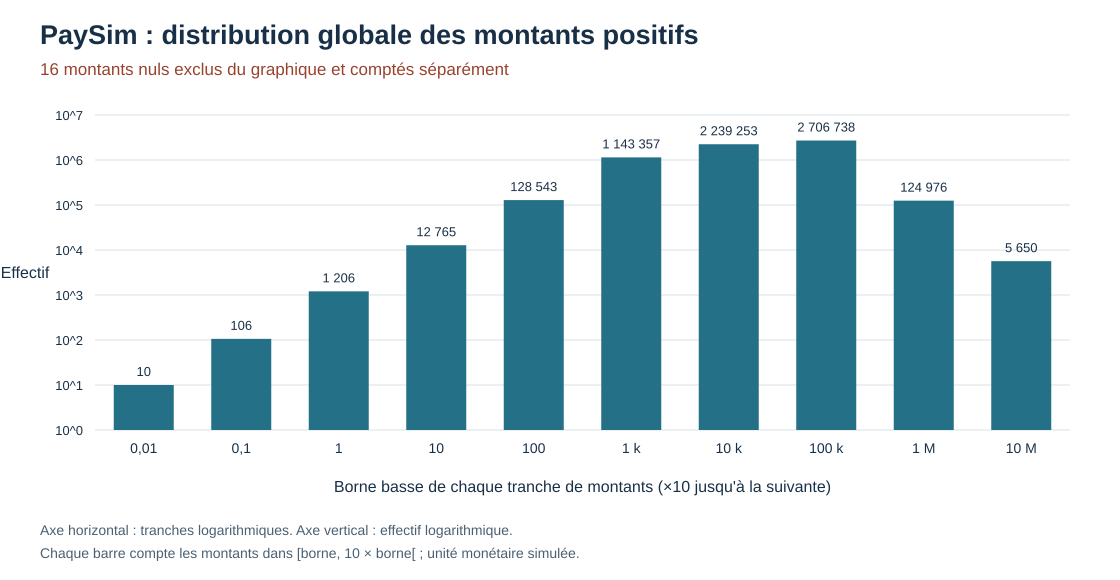

In [4]:
width, height = 1120, 580
left, right, top, bottom = 95, 1070, 115, 430
counts = bins["count"].to_list()
exponents = bins["exponent"].to_list()
max_power = 7
bar_width = (right - left) / len(counts)
y = lambda count: bottom - math.log10(count) / max_power * (bottom - top)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 44, "PaySim : distribution globale des montants positifs", size=27, weight="bold"),
         svg_text(40, 75, f"{format_int(summary['zeros'])} montants nuls exclus du graphique et comptés séparément", size=17, fill="#9a422e")]
for power in range(0, max_power + 1):
    value = 10 ** power
    ypos = y(value)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, f"10^{power}", size=13, anchor="end")]
labels = ["0,01", "0,1", "1", "10", "100", "1 k", "10 k", "100 k", "1 M", "10 M"]
for i, (exp, count) in enumerate(zip(exponents, counts)):
    center = left + (i + 0.5) * bar_width
    ypos = y(count)
    parts += [f'<rect x="{center - 30}" y="{ypos}" width="60" height="{bottom - ypos}" fill="#237087"/>',
              svg_text(center, max(ypos - 9, 103), format_int(count), size=13, anchor="middle"),
              svg_text(center, 453, labels[i], size=14, anchor="middle")]
parts += [svg_text((left + right) / 2, 492, "Borne basse de chaque tranche de montants (×10 jusqu'à la suivante)", size=16, anchor="middle"),
          svg_text(25, 278, "Effectif", size=16, anchor="middle"),
          svg_text(40, 535, "Axe horizontal : tranches logarithmiques. Axe vertical : effectif logarithmique.", size=14, fill="#4b6072"),
          svg_text(40, 558, "Chaque barre compte les montants dans [borne, 10 × borne[ ; unité monétaire simulée.", size=14, fill="#4b6072"),
          '</svg>']
amount_svg = save_svg("eda_montants_globaux.svg", "\n".join(parts))
show_svg(amount_svg)


## Vérification de l’hypothèse sur `log(amount)`

Le premier graphique des montants utilisait aussi un axe vertical logarithmique. Celui-ci utilise des tranches régulières de `log10(amount)` et un axe vertical linéaire pour examiner la forme de la distribution.


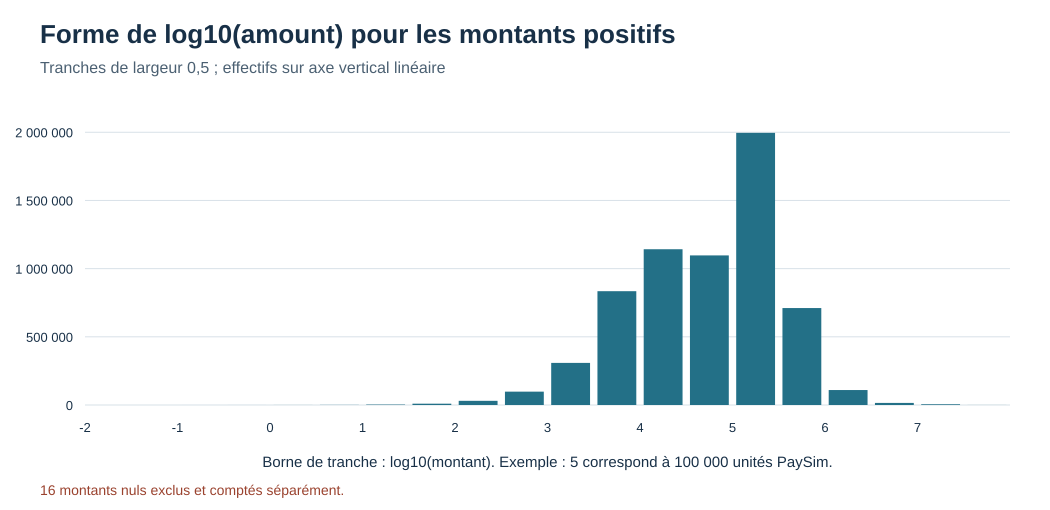

In [5]:
# Chaque tranche couvre 0,5 unité de log10(amount), soit un facteur 10**0,5.
log_bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns((pl.col("amount").log10() * 2).floor().cast(pl.Int32).alias("bin"))
    .group_by("bin").agg(pl.len().alias("count"))
    .sort("bin").collect()
)
assert sum(log_bins["count"].to_list()) == summary["total"] - summary["zeros"]
assert log_bins["bin"].to_list() == list(range(-4, 16))
log_stats = (
    frame.filter(pl.col("amount") > 0)
    .select(pl.col("amount").log10().mean().alias("mean"),
            pl.col("amount").log10().median().alias("median"),
            pl.col("amount").log10().skew().alias("skew"))
    .collect().row(0, named=True)
)
print("log10(amount), montants positifs :", log_stats)

width, height = 1050, 510
left, right, top, bottom = 85, 1010, 105, 405
counts = log_bins["count"].to_list()
bar_width = (right - left) / len(counts)
maximum = 2_200_000
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Forme de log10(amount) pour les montants positifs", size=26, weight="bold"),
         svg_text(40, 73, "Tranches de largeur 0,5 ; effectifs sur axe vertical linéaire", size=16, fill="#4b6072")]
for value in range(0, 2_000_001, 500_000):
    ypos = bottom - value / maximum * (bottom - top)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, format_int(value), size=13, anchor="end")]
for i, (bin_value, count) in enumerate(zip(log_bins["bin"].to_list(), counts)):
    center = left + (i + 0.5) * bar_width
    ypos = bottom - count / maximum * (bottom - top)
    parts.append(f'<rect x="{center - bar_width * 0.42}" y="{ypos}" width="{bar_width * 0.84}" height="{bottom - ypos}" fill="#237087"/>')
for log_value in range(-2, 9):
    i = 2 * (log_value + 2)
    if i < len(counts):
        xpos = left + i * bar_width
        parts.append(svg_text(xpos, 432, str(log_value), size=13, anchor="middle"))
parts += [svg_text((left + right) / 2, 467, "Borne de tranche : log10(montant). Exemple : 5 correspond à 100 000 unités PaySim.", size=15, anchor="middle"),
          svg_text(40, 495, "16 montants nuls exclus et comptés séparément.", size=14, fill="#9a422e"),
          '</svg>']
log_svg = save_svg("eda_log_montants.svg", "\n".join(parts))
show_svg(log_svg)


## Montants selon le label

Les tranches sont exactement celles de la vue précédente : largeur de 0,5 sur `log10(amount)`, plus les zéros séparés. Le premier graphique divise chaque effectif par le total de sa classe pour comparer les formes malgré le fort déséquilibre. Le second divise les fraudes de chaque tranche par toutes les transactions de cette même tranche pour obtenir son taux observé.


In [ ]:
# Tranches communes de largeur 0,5 sur log10(amount), plus une catégorie zéro.
class_bins = (
    frame.with_columns(
        pl.when(pl.col("amount") == 0).then(pl.lit(-999))
        .otherwise((pl.col("amount").log10() * 2).floor().cast(pl.Int32))
        .alias("bin")
    )
    .group_by("bin", "isFraud")
    .agg(pl.len().alias("count"))
    .sort("bin", "isFraud")
    .collect()
)
counts = {(bin_id, label): count for bin_id, label, count in class_bins.iter_rows()}
plot_bins = [-999, *range(-4, 16)]
rows = []
for bin_id in plot_bins:
    normal = counts.get((bin_id, 0), 0)
    fraud = counts.get((bin_id, 1), 0)
    total = normal + fraud
    rows.append({"bin": bin_id, "normal": normal, "fraud": fraud,
                 "total": total, "fraud_rate_pct": 100 * fraud / total if total else None,
                 "normal_class_pct": 100 * normal / summary["normal"],
                 "fraud_class_pct": 100 * fraud / summary["fraud"]})
assert sum(row["normal"] for row in rows) == summary["normal"]
assert sum(row["fraud"] for row in rows) == summary["fraud"]
assert sum(row["total"] for row in rows) == summary["total"]
assert abs(sum(row["normal_class_pct"] for row in rows) - 100) < 1e-9
assert abs(sum(row["fraud_class_pct"] for row in rows) - 100) < 1e-9
assert rows[0]["total"] == 16 and rows[0]["fraud"] == 16
assert [row["total"] for row in rows[1:]] == log_bins["count"].to_list()

def bin_label(bin_id):
    return "0" if bin_id == -999 else f"[{bin_id / 2:g}; {(bin_id + 1) / 2:g}["

print("log10(amount) : tranche [borne basse; borne haute[, sauf zéro")
print("tranche       total    fraudes  taux %")
for row in rows:
    print(f"{bin_label(row['bin']):>10}  {row['total']:>10}  {row['fraud']:>7}  {row['fraud_rate_pct']:>7.4f}")


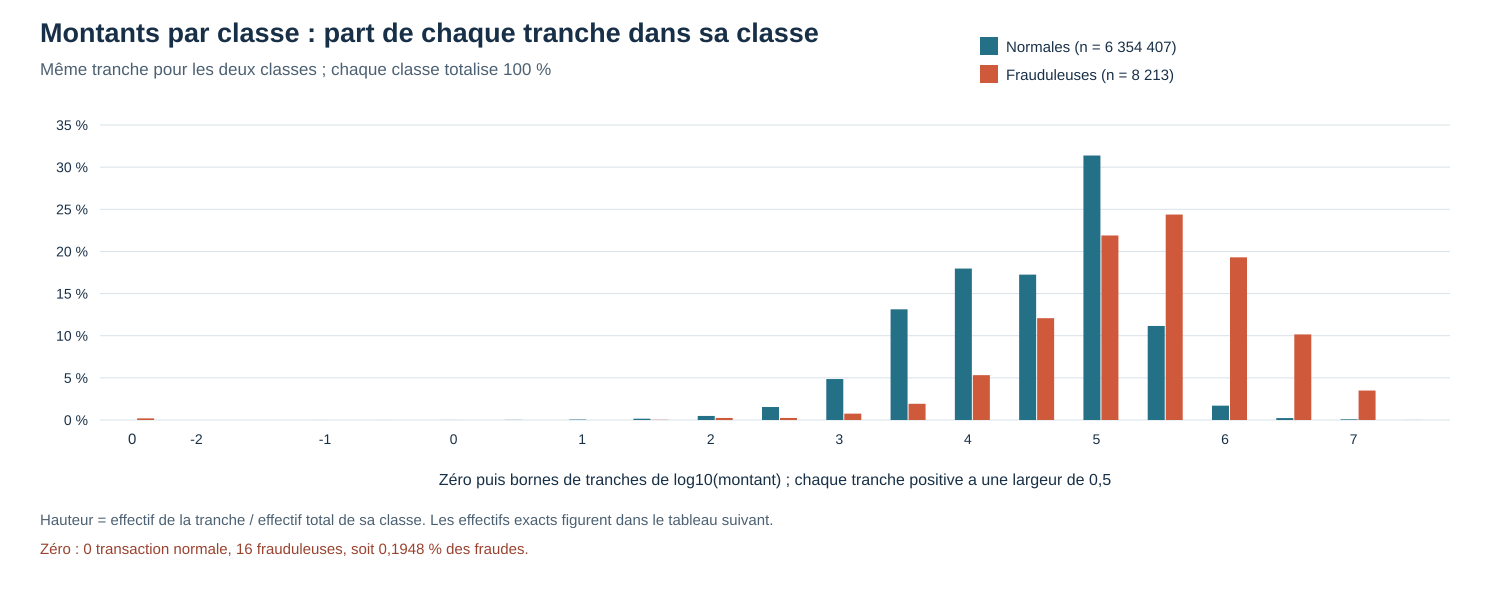

In [ ]:
width, height = 1500, 590
left, right, top, bottom = 100, 1450, 125, 420
bar_group = (right - left) / len(rows)
max_pct = 35
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 42, "Montants par classe : part de chaque tranche dans sa classe", size=27, weight="bold"),
         svg_text(40, 75, "Même tranche pour les deux classes ; chaque classe totalise 100 %", size=17, fill="#4b6072"),
         '<rect x="980" y="37" width="18" height="18" fill="#237087"/>',
         svg_text(1006, 52, f"Normales (n = {format_int(summary['normal'])})", size=15),
         '<rect x="980" y="65" width="18" height="18" fill="#ce593b"/>',
         svg_text(1006, 80, f"Frauduleuses (n = {format_int(summary['fraud'])})", size=15)]
for pct in range(0, max_pct + 1, 5):
    y = bottom - pct / max_pct * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 12, y + 5, f"{pct} %", size=14, anchor="end")]
for i, row in enumerate(rows):
    center = left + (i + .5) * bar_group
    for offset, value, color in [(-13, row["normal_class_pct"], "#237087"),
                                 (5, row["fraud_class_pct"], "#ce593b")]:
        y = bottom - value / max_pct * (bottom - top)
        parts.append(f'<rect x="{center + offset}" y="{y}" width="17" height="{bottom - y}" fill="{color}"/>')
    if i == 0:
        parts.append(svg_text(center, 444, "0", size=15, anchor="middle"))
    elif (row["bin"] + 4) % 2 == 0:
        parts.append(svg_text(center, 444, f"{row['bin'] / 2:g}", size=14, anchor="middle"))
parts += [svg_text((left + right) / 2, 485, "Zéro puis bornes de tranches de log10(montant) ; chaque tranche positive a une largeur de 0,5", size=16, anchor="middle"),
          svg_text(40, 525, "Hauteur = effectif de la tranche / effectif total de sa classe. Les effectifs exacts figurent dans le tableau suivant.", size=15, fill="#4b6072"),
          svg_text(40, 554, "Zéro : 0 transaction normale, 16 frauduleuses, soit 0,1948 % des fraudes.", size=15, fill="#9a422e"),
          '</svg>']
class_amount_svg = save_svg("eda_montants_par_classe.svg", "\n".join(parts))
show_svg(class_amount_svg)


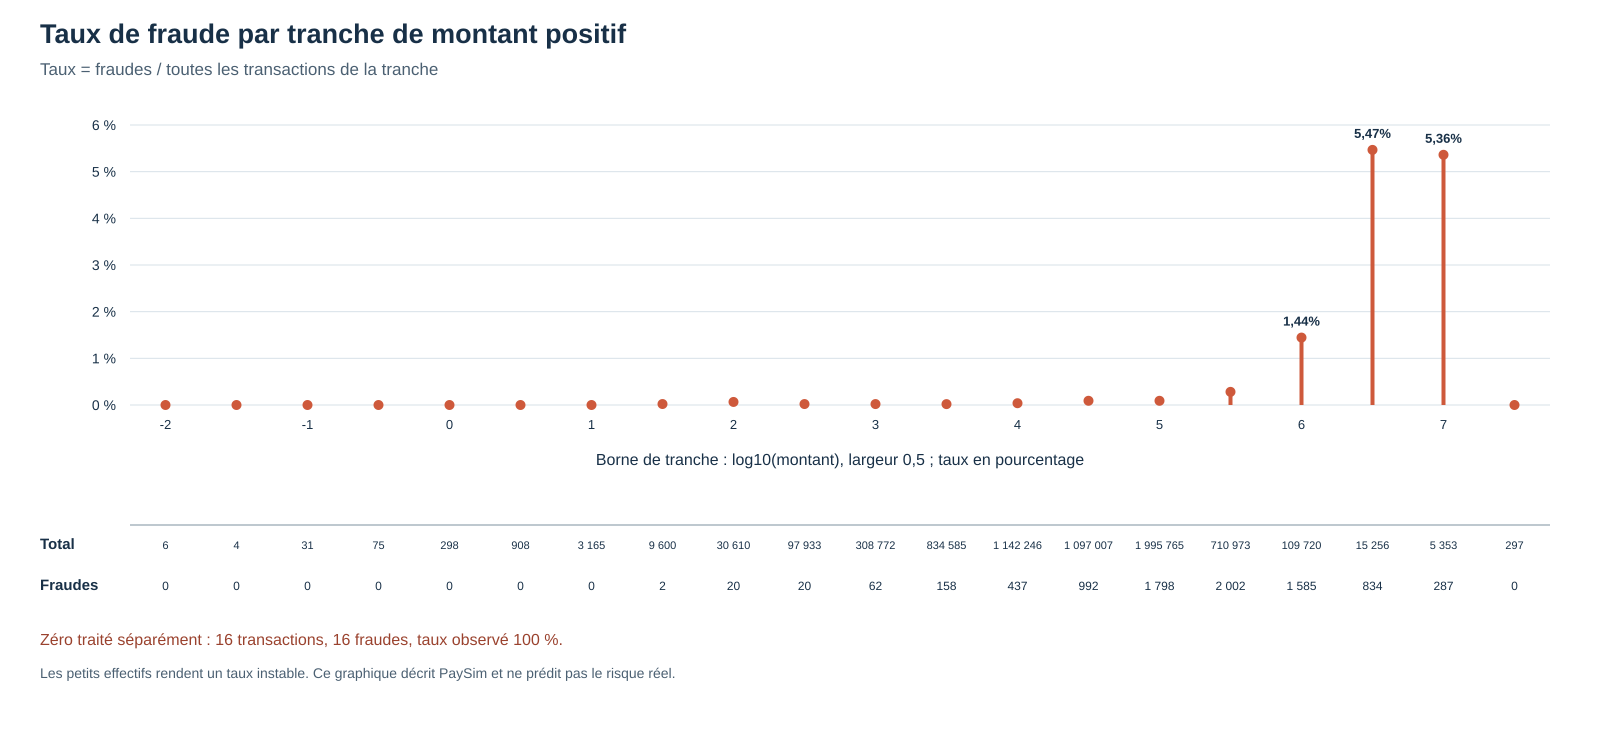

In [ ]:
width, height = 1600, 750
left, right, top, bottom = 130, 1550, 125, 405
positive = rows[1:]
slot = (right - left) / len(positive)
max_rate = 6.0
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Taux de fraude par tranche de montant positif", size=27, weight="bold"),
         svg_text(40, 75, "Taux = fraudes / toutes les transactions de la tranche", size=17, fill="#4b6072")]
for pct in range(0, 7):
    y = bottom - pct / max_rate * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 14, y + 5, f"{pct} %", size=14, anchor="end")]
for i, row in enumerate(positive):
    center = left + (i + .5) * slot
    y = bottom - row["fraud_rate_pct"] / max_rate * (bottom - top)
    parts += [f'<line x1="{center}" y1="{bottom}" x2="{center}" y2="{y}" stroke="#ce593b" stroke-width="4"/>',
              f'<circle cx="{center}" cy="{y}" r="5" fill="#ce593b"/>']
    if row["fraud_rate_pct"] >= 1:
        parts.append(svg_text(center, y - 12, f"{row['fraud_rate_pct']:.2f}%".replace(".", ","), size=13, anchor="middle", weight="bold"))
    if i % 2 == 0:
        parts.append(svg_text(center, 429, f"{row['bin'] / 2:g}", size=13, anchor="middle"))
parts += [svg_text((left + right) / 2, 465, "Borne de tranche : log10(montant), largeur 0,5 ; taux en pourcentage", size=16, anchor="middle"),
          f'<line x1="{left}" y1="525" x2="{right}" y2="525" stroke="#7d91a0"/>',
          svg_text(40, 549, "Total", size=15, weight="bold"),
          svg_text(40, 590, "Fraudes", size=15, weight="bold")]
for i, row in enumerate(positive):
    center = left + (i + .5) * slot
    parts += [svg_text(center, 549, format_int(row["total"]), size=11, anchor="middle"),
              svg_text(center, 590, format_int(row["fraud"]), size=12, anchor="middle")]
parts += [svg_text(40, 645, "Zéro traité séparément : 16 transactions, 16 fraudes, taux observé 100 %.", size=16, fill="#9a422e"),
          svg_text(40, 678, "Les petits effectifs rendent un taux instable. Ce graphique décrit PaySim et ne prédit pas le risque réel.", size=14, fill="#4b6072"),
          '</svg>']
rate_svg = save_svg("eda_taux_fraude_par_montant.svg", "\n".join(parts))
show_svg(rate_svg)


## Hypothèse 1 : rôle du type de transaction

Le type peut modifier la composition des tranches de montant. Nous conservons les mêmes bornes de montant, comptons toutes les combinaisons `type × tranche`, puis calculons le taux dans chaque combinaison. Les cinq tranches affichées couvrent 100 000 à environ 31,6 millions d'unités PaySim et répondent aux observations de l'utilisateur. Le calcul et les contrôles portent sur toutes les tranches, y compris zéro.


In [ ]:
# Même source et mêmes bornes que l'analyse des montants, avec le type en plus.
type_frame = pl.scan_csv(CSV).select("type", "amount", "isFraud")
type_bins = (
    type_frame.with_columns(
        pl.when(pl.col("amount") == 0).then(pl.lit(-999))
        .otherwise((pl.col("amount").log10() * 2).floor().cast(pl.Int32))
        .alias("bin")
    )
    .group_by("bin", "type")
    .agg(pl.len().alias("total"), pl.col("isFraud").sum().alias("fraud"))
    .sort("bin", "type").collect()
)
type_names = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
type_counts = {(bin_id, kind): (total, fraud)
               for bin_id, kind, total, fraud in type_bins.iter_rows()}
type_totals = {kind: (
    sum(type_counts.get((bin_id, kind), (0, 0))[0] for bin_id in plot_bins),
    sum(type_counts.get((bin_id, kind), (0, 0))[1] for bin_id in plot_bins)
) for kind in type_names}
assert sum(n for n, _ in type_totals.values()) == summary["total"]
assert sum(k for _, k in type_totals.values()) == summary["fraud"]
for row in rows:
    assert sum(type_counts.get((row["bin"], kind), (0, 0))[0] for kind in type_names) == row["total"]
    assert sum(type_counts.get((row["bin"], kind), (0, 0))[1] for kind in type_names) == row["fraud"]
assert type_counts.get((-999, "CASH_OUT")) == (16, 16)
focus_bins = [10, 11, 12, 13, 14]
focus_labels = ["100 k–316 k", "316 k–1 M", "1 M–3,16 M", "3,16 M–10 M", "10 M–31,6 M"]
print("Type : transactions, fraudes, taux observé")
for kind in type_names:
    n, k = type_totals[kind]
    print(kind, n, k, f"{100*k/n:.4f} %")
print("Par type et tranche : log10 borne basse, type, transactions, fraudes, taux observé")
for bin_id in focus_bins:
    for kind in type_names:
        n, k = type_counts.get((bin_id, kind), (0, 0))
        if n:
            print(bin_id / 2, kind, n, k, f"{100*k/n:.4f} %")


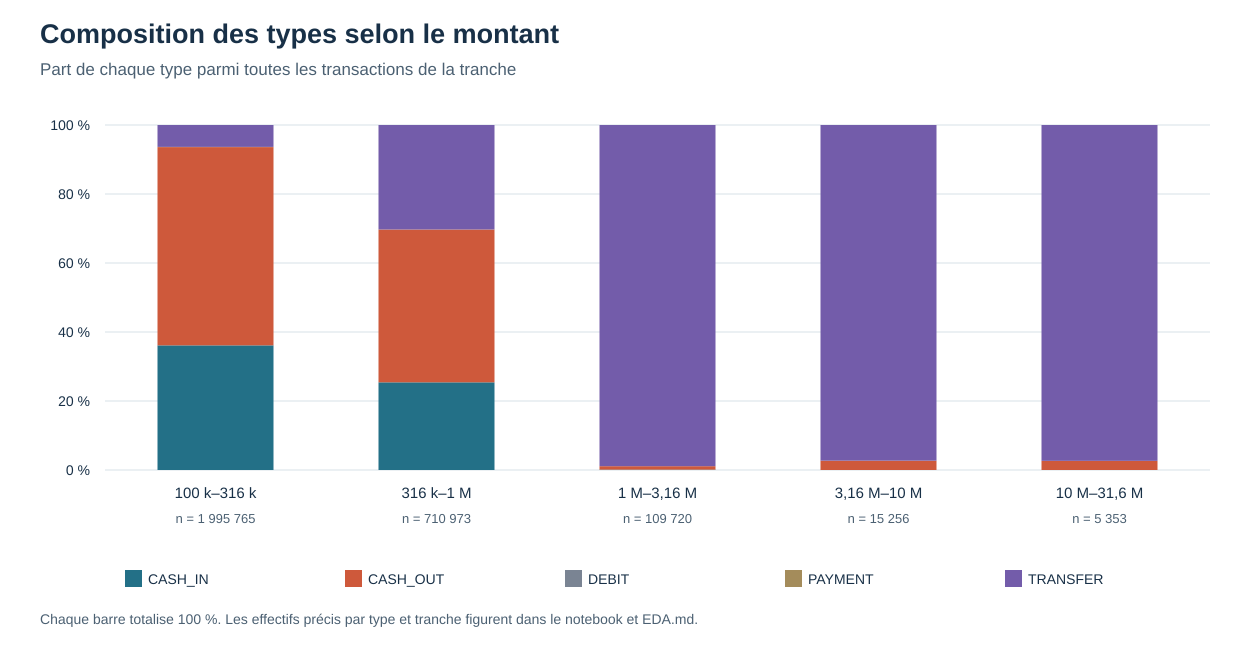

In [ ]:
width, height = 1260, 650
left, right, top, bottom = 105, 1210, 125, 470
colors = {"CASH_IN": "#237087", "CASH_OUT": "#ce593b", "DEBIT": "#7a8493",
          "PAYMENT": "#a48c5b", "TRANSFER": "#735caa"}
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Composition des types selon le montant", size=27, weight="bold"),
         svg_text(40, 75, "Part de chaque type parmi toutes les transactions de la tranche", size=17, fill="#4b6072")]
for pct in range(0, 101, 20):
    y = bottom - pct / 100 * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 15, y + 5, f"{pct} %", size=14, anchor="end")]
for i, bin_id in enumerate(focus_bins):
    center = left + (i + .5) * (right - left) / len(focus_bins)
    total = next(row["total"] for row in rows if row["bin"] == bin_id)
    y_bottom = bottom
    for kind in type_names:
        n, _ = type_counts.get((bin_id, kind), (0, 0))
        height_part = n / total * (bottom - top)
        y_bottom -= height_part
        parts.append(f'<rect x="{center-58}" y="{y_bottom}" width="116" height="{height_part}" fill="{colors[kind]}"/>')
    parts += [svg_text(center, 498, focus_labels[i], size=15, anchor="middle"),
              svg_text(center, 523, f"n = {format_int(total)}", size=13, anchor="middle", fill="#4b6072")]
legend_x = 125
for kind in type_names:
    parts += [f'<rect x="{legend_x}" y="570" width="17" height="17" fill="{colors[kind]}"/>',
              svg_text(legend_x + 23, 584, kind, size=14)]
    legend_x += 220
parts += [svg_text(40, 624, "Chaque barre totalise 100 %. Les effectifs précis par type et tranche figurent dans le notebook et EDA.md.", size=14, fill="#4b6072"),
          '</svg>']
composition_svg = save_svg("eda_composition_types_par_montant.svg", "\n".join(parts))
show_svg(composition_svg)


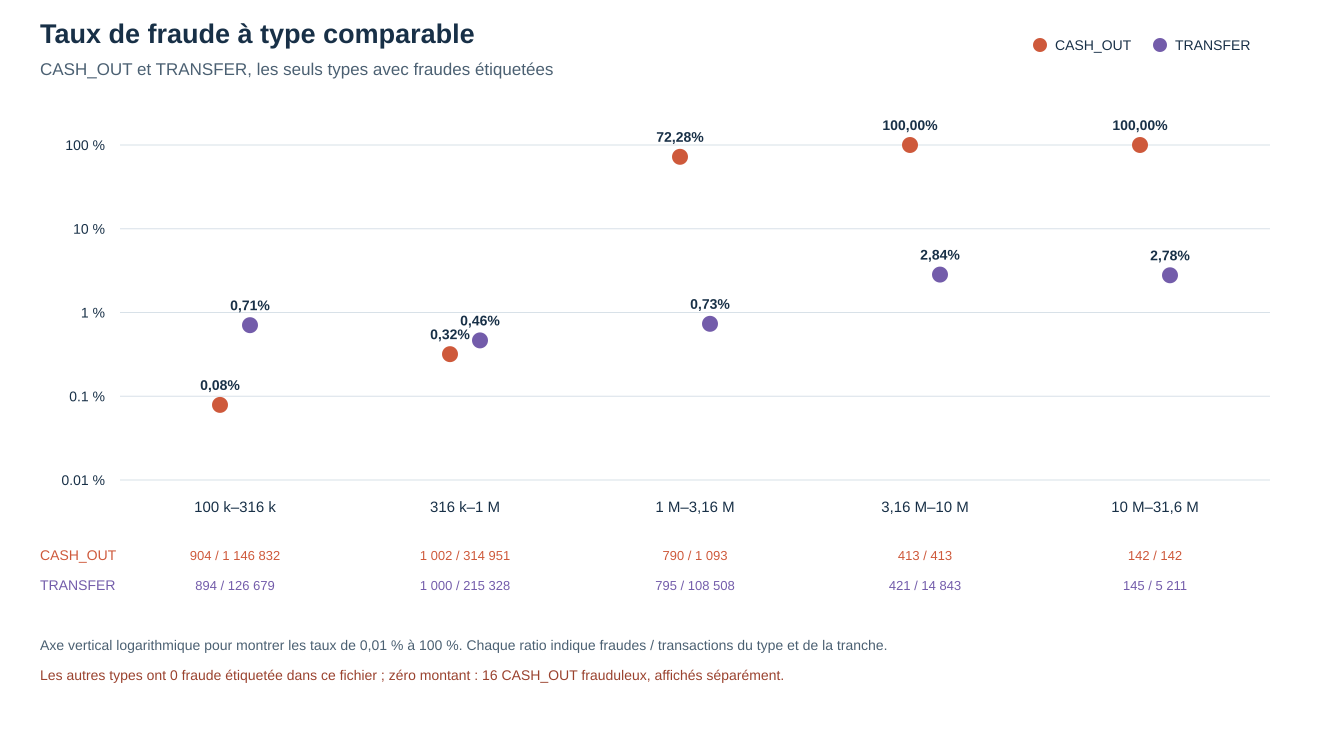

In [ ]:
width, height = 1320, 730
left, right, top, bottom = 120, 1270, 145, 480
colors = {"CASH_OUT": "#ce593b", "TRANSFER": "#735caa"}
log_min, log_max = -2.0, 2.0
ypos = lambda rate: bottom - (math.log10(rate) - log_min) / (log_max - log_min) * (bottom - top)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Taux de fraude à type comparable", size=27, weight="bold"),
         svg_text(40, 75, "CASH_OUT et TRANSFER, les seuls types avec fraudes étiquetées", size=17, fill="#4b6072"),
         '<circle cx="1040" cy="45" r="7" fill="#ce593b"/>',
         svg_text(1055, 50, "CASH_OUT", size=14),
         '<circle cx="1160" cy="45" r="7" fill="#735caa"/>',
         svg_text(1175, 50, "TRANSFER", size=14)]
for rate_tick in [0.01, 0.1, 1, 10, 100]:
    y = ypos(rate_tick)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 15, y + 5, f"{rate_tick:g} %", size=14, anchor="end")]
for i, bin_id in enumerate(focus_bins):
    center = left + (i + .5) * (right - left) / len(focus_bins)
    for dx, kind in [(-15, "CASH_OUT"), (15, "TRANSFER")]:
        n, k = type_counts[(bin_id, kind)]
        rate_value = 100 * k / n
        y = ypos(rate_value)
        parts += [f'<circle cx="{center+dx}" cy="{y}" r="8" fill="{colors[kind]}"/>',
                  svg_text(center + dx, y - 15, f"{rate_value:.2f}%".replace(".", ","), size=14, anchor="middle", weight="bold")]
    parts += [svg_text(center, 512, focus_labels[i], size=15, anchor="middle"),
              svg_text(center, 560, f"{format_int(type_counts[(bin_id, 'CASH_OUT')][1])} / {format_int(type_counts[(bin_id, 'CASH_OUT')][0])}", size=13, anchor="middle", fill=colors["CASH_OUT"]),
              svg_text(center, 590, f"{format_int(type_counts[(bin_id, 'TRANSFER')][1])} / {format_int(type_counts[(bin_id, 'TRANSFER')][0])}", size=13, anchor="middle", fill=colors["TRANSFER"])]
parts += [svg_text(40, 560, "CASH_OUT", size=14, fill=colors["CASH_OUT"]),
          svg_text(40, 590, "TRANSFER", size=14, fill=colors["TRANSFER"]),
          svg_text(40, 650, "Axe vertical logarithmique pour montrer les taux de 0,01 % à 100 %. Chaque ratio indique fraudes / transactions du type et de la tranche.", size=14, fill="#4b6072"),
          svg_text(40, 680, "Les autres types ont 0 fraude étiquetée dans ce fichier ; zéro montant : 16 CASH_OUT frauduleux, affichés séparément.", size=14, fill="#9a422e"),
          '</svg>']
type_rate_svg = save_svg("eda_taux_par_type_et_montant.svg", "\n".join(parts))
show_svg(type_rate_svg)


## Hypothèse sur les soldes d’origine

Nous vérifions le solde **avant** transaction, sans utiliser les soldes après transaction comme variables. Pour les montants positifs de `CASH_OUT` et `TRANSFER`, `solde ≈ montant` signifie un écart absolu inférieur à 0,005 unité, soit moins d’un demi-centime. Les montants nuls sont exclus de cette comparaison pour ne pas confondre `0 = 0` avec le vidage d’un compte. Le graphique compare cette égalité selon le type et le label, sans entraîner de modèle.


In [ ]:
# Analyse descriptive du solde d'origine avant transaction.
# Les montants nuls sont isolés, car zéro == zéro ne décrirait pas un compte vidé.
balance_frame = (
    pl.scan_csv(CSV).select("type", "amount", "oldbalanceOrg", "isFraud")
    .filter((pl.col("amount") > 0) & pl.col("type").is_in(["CASH_OUT", "TRANSFER"]))
    .with_columns(
        ((pl.col("oldbalanceOrg") - pl.col("amount")).abs() < 0.005).alias("equal_to_cent"),
        (pl.col("oldbalanceOrg") >= pl.col("amount")).alias("enough_balance"),
        (pl.col("oldbalanceOrg") == 0).alias("zero_balance"),
        (pl.col("amount").log10() * 2).floor().cast(pl.Int32).alias("bin"),
    )
)
balance_summary = (
    balance_frame.group_by("type", "isFraud")
    .agg(pl.len().alias("total"), pl.col("equal_to_cent").sum().alias("equal"),
         pl.col("enough_balance").sum().alias("enough"),
         pl.col("zero_balance").sum().alias("zero_balance"),
         pl.col("oldbalanceOrg").median().alias("median_old"))
    .sort("type", "isFraud").collect()
)
balance_rows = {(kind, label): {"total": total, "equal": equal, "enough": enough,
                                "zero_balance": zero_balance, "median_old": median_old}
                for kind, label, total, equal, enough, zero_balance, median_old
                in balance_summary.iter_rows()}
assert balance_rows[("CASH_OUT", 1)]["total"] == 4_100  # 16 montants nuls isolés.
assert balance_rows[("TRANSFER", 1)]["total"] == 4_097
assert balance_rows[("CASH_OUT", 0)]["equal"] == 0
assert balance_rows[("TRANSFER", 0)]["equal"] == 0
assert sum(row["total"] for row in balance_rows.values()) == 2_770_393

large_cashout = (
    balance_frame.filter((pl.col("type") == "CASH_OUT") & pl.col("bin").is_in([10, 11, 12, 13, 14]))
    .group_by("bin", "isFraud")
    .agg(pl.len().alias("total"), pl.col("equal_to_cent").sum().alias("equal"),
         pl.col("enough_balance").sum().alias("enough"),
         pl.col("zero_balance").sum().alias("zero_balance"),
         pl.col("oldbalanceOrg").median().alias("median_old"),
         pl.col("amount").median().alias("median_amount"))
    .sort("bin", "isFraud").collect()
)
print("Type, label, total, solde≈montant, solde≥montant, solde nul, médiane du solde")
for kind, label, total, equal, enough, zero_balance, median_old in balance_summary.iter_rows():
    print(kind, label, total, equal, enough, zero_balance, median_old)
print("Gros CASH_OUT : tranche, label, total, solde≈montant, solde≥montant, solde nul, médiane solde, médiane montant")
for row in large_cashout.iter_rows():
    print(row)


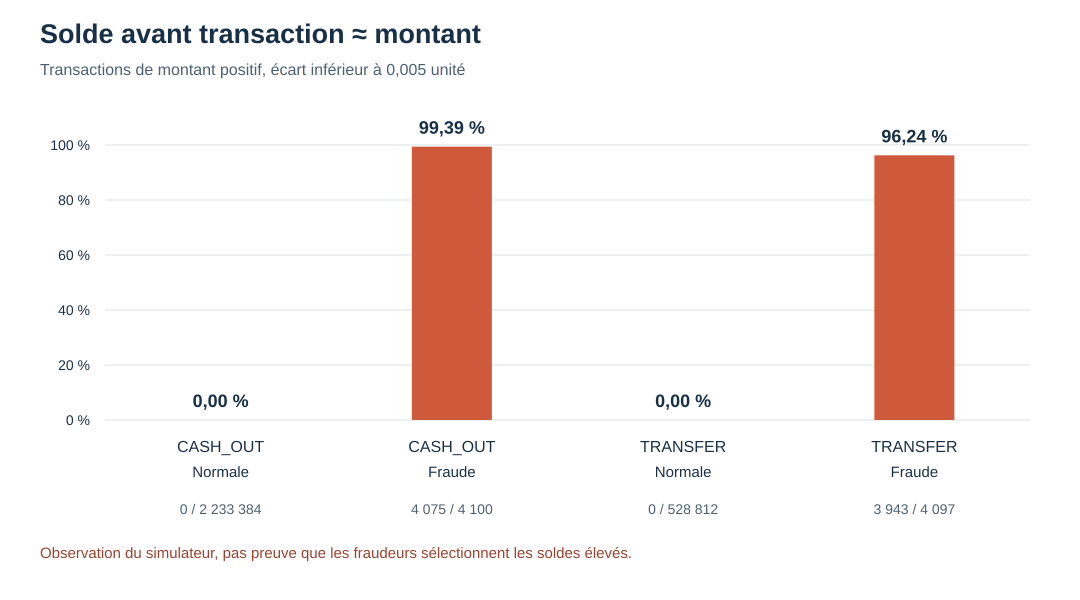

In [ ]:
width, height = 1080, 600
left, right, top, bottom = 105, 1030, 145, 420
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Solde avant transaction ≈ montant", size=27, weight="bold"),
         svg_text(40, 75, "Transactions de montant positif, écart inférieur à 0,005 unité", size=16, fill="#4b6072")]
for pct in range(0, 101, 20):
    y = bottom - pct / 100 * (bottom - top)
    parts += [f'<line x1="{left}" y1="{y}" x2="{right}" y2="{y}" stroke="#d8e1e8"/>',
              svg_text(left - 15, y + 5, f"{pct} %", size=14, anchor="end")]
groups = [("CASH_OUT", 0), ("CASH_OUT", 1), ("TRANSFER", 0), ("TRANSFER", 1)]
for i, (kind, label) in enumerate(groups):
    row = balance_rows[(kind, label)]
    pct = 100 * row["equal"] / row["total"]
    center = left + (i + .5) * (right - left) / len(groups)
    y = bottom - pct / 100 * (bottom - top)
    color = "#ce593b" if label else "#237087"
    parts += [f'<rect x="{center-40}" y="{y}" width="80" height="{bottom-y}" fill="{color}"/>',
              svg_text(center, max(y - 13, 128), f"{pct:.2f} %".replace(".", ","), size=18, anchor="middle", weight="bold"),
              svg_text(center, 452, kind, size=16, anchor="middle"),
              svg_text(center, 477, "Fraude" if label else "Normale", size=15, anchor="middle"),
              svg_text(center, 514, f"{format_int(row['equal'])} / {format_int(row['total'])}", size=14, anchor="middle", fill="#4b6072")]
parts += [svg_text(40, 558, "Observation du simulateur, pas preuve que les fraudeurs sélectionnent les soldes élevés.", size=15, fill="#9a422e"),
          '</svg>']
balance_svg = save_svg("eda_solde_egal_montant.svg", "\n".join(parts))
show_svg(balance_svg)


## Vérifier si le solde enregistré après transaction est nul

Cette vérification répond à la question « vider le compte » : elle lit `newbalanceOrig` hors ligne, sans le proposer comme variable au scoring. Les montants nuls restent exclus.


In [ ]:
# Vérification descriptive du solde après transaction ; jamais variable du modèle avant exécution.
post_balance_check = (
    pl.scan_csv(CSV).select("type", "amount", "oldbalanceOrg", "newbalanceOrig", "isFraud")
    .filter((pl.col("amount") > 0) & pl.col("type").is_in(["CASH_OUT", "TRANSFER"]))
    .with_columns(
        ((pl.col("oldbalanceOrg") - pl.col("amount")).abs() < 0.005).alias("old_eq_amount"),
        (pl.col("newbalanceOrig") == 0).alias("new_zero"),
    )
    .group_by("type", "isFraud")
    .agg(pl.len().alias("total"),
         pl.col("old_eq_amount").sum().alias("old_eq_amount"),
         pl.col("new_zero").sum().alias("new_zero"),
         (pl.col("old_eq_amount") & pl.col("new_zero")).sum().alias("both"))
    .sort("type", "isFraud").collect()
)
assert post_balance_check.filter(pl.col("isFraud") == 1)["total"].sum() == 8_197
print(post_balance_check)


## Prochaine discussion

Le rapport entre `oldbalanceOrg` et `amount` apparaît presque déterministe dans PaySim. Il faudra décider si ce solde peut figurer dans un modèle présenté comme utilisable avant exécution, compte tenu du risque de signature du simulateur. Nous n’inférons pas l’intention des fraudeurs ni la traçabilité des transferts à partir de ce CSV.


## Hypothèse temporelle : volume et taux selon `step`

Les périodes descriptives sont fixées à 48 steps : `[1, 48]`, `[49, 96]`, etc. Comme un step représente une heure simulée, chaque période complète couvre deux jours simulés. La dernière `[721, 743]` ne couvre que 23 steps. Ces fenêtres servent uniquement à décrire les données, sans définir les futurs ensembles d'entraînement. Les taux sont toujours accompagnés du nombre de transactions et de fraudes. Une période est signalée comme peu fournie lorsque son dénominateur est inférieur à 10 000 transactions ; cette borne est un repère de lecture, pas un seuil statistique.

Les graphiques utilisent une échelle logarithmique verticale pour garder lisibles les fortes amplitudes. Elle ne peut représenter ni zéro transaction ni un taux nul ; les tableaux imprimés préservent tous les effectifs et la vérification explicite qu'aucune des périodes tracées n'a un taux nul.


In [ ]:
# Lecture hors ligne des labels pour l'EDA seulement.
WINDOW = 48
LOW_COUNT = 10_000
temporal = (
    pl.scan_csv(CSV).select("step", "type", "isFraud")
    .with_columns((((pl.col("step") - 1) // WINDOW) * WINDOW + 1).alias("start"))
)
periods = (
    temporal.group_by("start")
    .agg(pl.len().alias("transactions"), pl.col("isFraud").sum().alias("fraudes"),
         pl.col("step").min().alias("min_step"), pl.col("step").max().alias("max_step"))
    .sort("start").collect()
)
by_type = (
    temporal.filter(pl.col("type").is_in(["CASH_OUT", "TRANSFER"]))
    .group_by("start", "type")
    .agg(pl.len().alias("transactions"), pl.col("isFraud").sum().alias("fraudes"))
    .sort("start", "type").collect()
)
assert periods["start"].to_list() == list(range(1, 744, WINDOW))
assert periods["transactions"].sum() == summary["total"]
assert periods["fraudes"].sum() == summary["fraud"]
assert by_type["fraudes"].sum() == summary["fraud"]
assert by_type.group_by("type").agg(pl.col("transactions").sum(), pl.col("fraudes").sum()).sort("type")["transactions"].to_list() == [2_237_500, 532_909]
assert all(row["fraudes"] > 0 for row in periods.iter_rows(named=True))
assert all(row["fraudes"] > 0 for row in by_type.iter_rows(named=True))
period_rows = periods.to_dicts()
type_lookup = {(row["start"], row["type"]): row for row in by_type.iter_rows(named=True)}
for row in period_rows:
    start = row["start"]
    assert row["min_step"] == start and row["max_step"] == min(start + 47, 743)
    assert sum(type_lookup[(start, kind)]["fraudes"] for kind in ("CASH_OUT", "TRANSFER")) == row["fraudes"]
    print(f'{start:3d}-{row["max_step"]:3d} | total {row["transactions"]:7d} | fraude {row["fraudes"]:3d} | taux {100*row["fraudes"]/row["transactions"]:7.4f}% | '
          + ' | '.join(f'{kind} {type_lookup[(start, kind)]["fraudes"]}/{type_lookup[(start, kind)]["transactions"]} '
                       f'({100*type_lookup[(start, kind)]["fraudes"]/type_lookup[(start, kind)]["transactions"]:.4f}%)'
                       for kind in ("CASH_OUT", "TRANSFER")))


In [ ]:
# Figure 1 : deux panneaux avec les mêmes périodes sur l'axe horizontal.
width, height = 1800, 1000
left, right = 125, 1750
xs = [left + (i + 0.5) * (right - left) / len(period_rows) for i in range(len(period_rows))]
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         svg_text(55, 48, "PaySim : volume et taux de fraude par 48 steps", size=29, weight="bold"),
         svg_text(55, 80, "Fenêtres fixes de deux jours simulés ; dernière fenêtre de 23 steps", size=17, fill="#4b6072")]
# Echelle logarithmique du volume : 10^2 à 10^7.
y_volume = lambda n: 370 - (math.log10(n) - 2) / 5 * 245
for p in range(2, 7):
    yy = y_volume(10**p)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left - 15, yy + 5, f"10^{p}", size=13, anchor="end")]
parts += [svg_text(55, 130, "A. Transactions par période", size=21, weight="bold"),
          svg_text(55, 155, "Axe vertical : effectif (log)", size=14, fill="#4b6072")]
for x, row in zip(xs, period_rows):
    yy = y_volume(row["transactions"])
    color = "#ce593b" if row["transactions"] < LOW_COUNT else "#237087"
    parts.append(f'<rect x="{x-25:.1f}" y="{yy:.1f}" width="50" height="{370-yy:.1f}" fill="{color}"/>')
# Echelle logarithmique du taux en pourcentage : 0,01 % à 100 %.
y_rate = lambda pct: 750 - (math.log10(pct) + 2) / 4 * 245
for value, label in [(0.01,"0,01"),(0.1,"0,1"),(1,"1"),(10,"10"),(100,"100")]:
    yy = y_rate(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left - 15, yy + 5, label + " %", size=13, anchor="end")]
parts += [svg_text(55, 455, "B. Taux de fraude par période", size=21, weight="bold"),
          svg_text(55, 480, "Axe vertical : fraudes / transactions (log)", size=14, fill="#4b6072")]
points = [(x, y_rate(100*row["fraudes"]/row["transactions"])) for x,row in zip(xs,period_rows)]
parts.append('<polyline points="' + ' '.join(f'{x:.1f},{y:.1f}' for x,y in points) + '" fill="none" stroke="#ce593b" stroke-width="3"/>')
for (x, yy), row in zip(points, period_rows):
    parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="6" fill="#ce593b"/>')
    if row["transactions"] < LOW_COUNT:
        parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="11" fill="none" stroke="#172d40" stroke-width="2"/>')
parts += [svg_text(55, 793, "Période", size=13, fill="#4b6072"),
          svg_text(55, 823, "n total", size=13, fill="#4b6072"),
          svg_text(55, 846, "n fraudes", size=13, fill="#4b6072")]
for x, row in zip(xs, period_rows):
    parts += [svg_text(x, 793, f'{row["start"]}-{row["max_step"]}', size=12, anchor="middle"),
              svg_text(x, 823, format_int(row["transactions"]), size=12, anchor="middle"),
              svg_text(x, 846, format_int(row["fraudes"]), size=12, anchor="middle")]
parts += [svg_text(55, 905, "Cercle entouré et barre orange : moins de 10 000 transactions dans la période.", size=16, fill="#9a422e"),
          svg_text(55, 934, "Le taux de la période 721-743 est 272/272 = 100 % ; ce sont 23 steps et 272 lignes seulement.", size=16, fill="#4b6072"),
          '</svg>']
time_global_svg = save_svg("eda_temps_volume_taux.svg", "\n".join(parts))
show_svg(time_global_svg)


In [ ]:
# Figure 2 : mêmes fenêtres pour les deux types, avec dénominateurs affichés.
width, height = 1800, 840
left, right = 125, 1750
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         svg_text(55, 48, "PaySim : taux de fraude par type et période", size=29, weight="bold"),
         svg_text(55, 78, "Mêmes fenêtres de 48 steps ; taux calculé au sein de chaque type", size=17, fill="#4b6072")]
y_type = lambda pct: 540 - (math.log10(pct) + 2) / 4 * 405
for value, label in [(0.01,"0,01"),(0.1,"0,1"),(1,"1"),(10,"10"),(100,"100")]:
    yy = y_type(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left - 15, yy + 5, label + " %", size=14, anchor="end")]
parts += [svg_text(55, 108, "Axe vertical : fraudes / transactions du type (log)", size=15, fill="#4b6072"),
          f'<line x1="1360" y1="103" x2="1395" y2="103" stroke="#ce593b" stroke-width="3"/>',
          svg_text(1404, 109, "CASH_OUT", size=16),
          f'<line x1="1530" y1="103" x2="1565" y2="103" stroke="#735caa" stroke-width="3"/>',
          svg_text(1574, 109, "TRANSFER", size=16)]
for kind, color in [("CASH_OUT", "#ce593b"), ("TRANSFER", "#735caa")]:
    points = []
    for x, row in zip(xs, period_rows):
        item = type_lookup[(row["start"], kind)]
        points.append((x, y_type(100*item["fraudes"]/item["transactions"])))
    parts.append('<polyline points="' + ' '.join(f'{x:.1f},{y:.1f}' for x,y in points) + f'" fill="none" stroke="{color}" stroke-width="3"/>')
    for (x, yy), row in zip(points, period_rows):
        item = type_lookup[(row["start"], kind)]
        parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="5" fill="{color}"/>')
        if item["transactions"] < LOW_COUNT:
            parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="10" fill="none" stroke="#172d40" stroke-width="2"/>')
parts += [svg_text(55, 582, "Période", size=13, fill="#4b6072"),
          svg_text(55, 612, "CASH_OUT n/f", size=13, fill="#ce593b"),
          svg_text(55, 640, "TRANSFER n/f", size=13, fill="#735caa")]
for x, row in zip(xs, period_rows):
    parts.append(svg_text(x, 582, f'{row["start"]}-{row["max_step"]}', size=12, anchor="middle"))
    for yy, kind in [(612,"CASH_OUT"),(640,"TRANSFER")]:
        item = type_lookup[(row["start"], kind)]
        parts.append(svg_text(x, yy, f'{item["transactions"]}/{item["fraudes"]}', size=11, anchor="middle"))
parts += [svg_text(55, 712, "n/f = transactions / fraudes. Cercle entouré : moins de 10 000 transactions pour ce type et cette période.", size=15, fill="#4b6072"),
          svg_text(55, 744, "Dernière période : 136/136 CASH_OUT et 136/136 TRANSFER, soit 100 % dans chaque type.", size=16, fill="#9a422e"),
          '</svg>']
time_types_svg = save_svg("eda_temps_taux_par_type.svg", "\n".join(parts))
show_svg(time_types_svg)


## Discussion avec l'utilisateur

Les variations de taux doivent être lues avec les volumes, la composition par type et la fenêtre finale courte. Nous n'attribuons pas de cause au mécanisme du simulateur à partir de ces graphiques. Nous attendons les observations de l'utilisateur avant d'explorer les montants ou les soldes selon le temps, et avant de choisir des frontières train/validation/test.


## Diagnostic de la fin de série et de la symétrie des fraudes

Le dernier **step** est distinct de la dernière **fenêtre**. Compter les steps composés uniquement de fraudes sur tout le fichier permet de savoir si 721 à 743 est un cas unique. Comparer les nombres de fraudes des deux types au même step vérifie le motif visuel des courbes. Enfin, un rapprochement sur `(step, amount)` mesure des correspondances descriptives, sans supposer qu'il s'agit d'une même opération ou du même compte.


In [ ]:
# Contrôles descriptifs ; aucun filtrage des données ni entraînement.
by_step = (
    temporal.group_by("step")
    .agg(pl.len().alias("transactions"), pl.col("isFraud").sum().alias("fraudes"))
    .sort("step").collect()
)
all_fraud_steps = by_step.filter(pl.col("transactions") == pl.col("fraudes"))
tail_23 = by_step.filter(pl.col("step") >= 721)
last_step = by_step.filter(pl.col("step") == 743).row(0, named=True)
assert by_step.height == 743 and by_step["transactions"].sum() == summary["total"]
assert by_step["fraudes"].sum() == summary["fraud"]
assert tail_23.height == 23 and tail_23["transactions"].sum() == 272
assert tail_23["fraudes"].sum() == 272
print("Steps tout-fraude :", all_fraud_steps.height, "/", by_step.height,
      "; lignes :", all_fraud_steps["transactions"].sum(),
      "; part des fraudes :", 100*all_fraud_steps["fraudes"].sum()/summary["fraud"])
print("Dernière fenêtre 721-743 :", tail_23["transactions"].sum(), "lignes/fraudes ; dernière heure :", last_step)

fraud_by_step_type = (
    temporal.filter(pl.col("type").is_in(["CASH_OUT", "TRANSFER"]))
    .group_by("step", "type").agg(pl.col("isFraud").sum().alias("fraudes"))
    .collect().pivot(on="type", index="step", values="fraudes")
    .fill_null(0).sort("step")
)
assert fraud_by_step_type.height == 743
assert set(fraud_by_step_type.columns) == {"step", "CASH_OUT", "TRANSFER"}
fraud_by_step_type = fraud_by_step_type.with_columns(
    (pl.col("CASH_OUT") - pl.col("TRANSFER")).alias("ecart")
)
print("Steps avec nombres de fraudes égaux :", fraud_by_step_type.filter(pl.col("ecart") == 0).height)
print("Corrélation descriptive de Pearson des nombres de fraudes par step :",
      fraud_by_step_type.select(pl.corr("CASH_OUT", "TRANSFER")).item())
print("Écarts entre les deux nombres de fraudes :",
      fraud_by_step_type["ecart"].value_counts().sort("ecart"))

fraud_amounts = pl.scan_csv(CSV).filter(pl.col("isFraud") == 1).select("step", "type", "amount")
cashout_amounts = fraud_amounts.filter(pl.col("type") == "CASH_OUT").group_by("step", "amount").agg(pl.len().alias("cashout"))
transfer_amounts = fraud_amounts.filter(pl.col("type") == "TRANSFER").group_by("step", "amount").agg(pl.len().alias("transfer"))
matched_amounts = cashout_amounts.join(transfer_amounts, on=["step", "amount"], how="inner").collect()
matching_count = matched_amounts.select(pl.min_horizontal("cashout", "transfer").sum()).item()
assert matching_count <= min(4_116, 4_097)
print("Fraudes appariables par même step et même montant :", matching_count,
      "/ 4 097 TRANSFER et / 4 116 CASH_OUT")


**Interprétation provisoire.** `step` est disponible au moment de la transaction, mais le conserver comme variable prédictive pourrait apprendre le calendrier de génération des labels dans PaySim. Le retirer comme variable du modèle ne retire pas son rôle dans un futur découpage temporel. Exclure seulement la dernière heure ou les 23 derniers steps ne résoudrait pas les autres steps tout-fraude ; toute éventuelle exclusion devra être justifiée avant l'entraînement et rapportée avec son périmètre. Les correspondances `(step, amount)` ne prouvent aucun lien entre comptes ou transactions.


## Diagnostic limité : comptes des `TRANSFER` et `CASH_OUT` candidats

L'analyse hors ligne conserve seulement les transactions étiquetées fraude et les groupes ayant au moins un `TRANSFER` et un `CASH_OUT` avec exactement le même `(step, amount)`. Elle compte d'abord les groupes et les transactions **distinctes** de chaque type. Un groupe est ambigu pour un appariement par montant si au moins un type compte plusieurs transactions. La jointure de compte exige ensuite `TRANSFER.nameDest == CASH_OUT.nameOrig` en plus de `step` et `amount`. Des identifiants de lignes internes à cette EDA servent seulement à dédupliquer les résultats d'une jointure éventuelle ; ils n'indiquent aucun ordre temporel.


In [ ]:
# Les identifiants ci-dessous repèrent les lignes de l'EDA, pas une chronologie.
fraud_accounts = (
    pl.scan_csv(CSV).filter(pl.col("isFraud") == 1)
    .select("step", "type", "amount", "nameOrig", "nameDest")
    .collect().with_row_index("eda_row_id")
)
transfers = fraud_accounts.filter(pl.col("type") == "TRANSFER")
cashouts = fraud_accounts.filter(pl.col("type") == "CASH_OUT")
assert transfers.height == 4_097 and cashouts.height == 4_116
transfer_groups = transfers.group_by("step", "amount").agg(pl.len().alias("n_transfer"))
cashout_groups = cashouts.group_by("step", "amount").agg(pl.len().alias("n_cashout"))
candidate_groups = transfer_groups.join(cashout_groups, on=["step", "amount"], how="inner").sort("step", "amount")
ambiguous_groups = candidate_groups.filter((pl.col("n_transfer") > 1) | (pl.col("n_cashout") > 1))
amount_pair_upper_bound = candidate_groups.select(pl.min_horizontal("n_transfer", "n_cashout").sum()).item()
assert candidate_groups.height == 4_023 and amount_pair_upper_bound == matching_count == 4_075
print("Groupes avec même step et montant :", candidate_groups.height)
print("Transactions ayant au moins un candidat par montant : TRANSFER", candidate_groups["n_transfer"].sum(),
      "; CASH_OUT", candidate_groups["n_cashout"].sum())
print("Groupes ambigus par montant :", ambiguous_groups.height,
      "; transactions dans ces groupes : TRANSFER", ambiguous_groups["n_transfer"].sum(),
      "; CASH_OUT", ambiguous_groups["n_cashout"].sum())
print("Maximum appariable un-à-un sur montant seul :", amount_pair_upper_bound,
      "de chaque type ; une jointure brute produirait",
      candidate_groups.select((pl.col("n_transfer") * pl.col("n_cashout")).sum()).item(),
      "combinaisons, pas autant de paires indépendantes")

# La condition de compte complète les deux clés communes. Chaque transaction liée est comptée une seule fois.
account_links = (
    transfers.select("eda_row_id", "step", "amount", pl.col("nameDest").alias("account"))
    .join(cashouts.select("eda_row_id", "step", "amount", pl.col("nameOrig").alias("account")),
          on=["step", "amount", "account"], how="inner", suffix="_cashout")
)
linked_groups = account_links.select("step", "amount").unique().height
linked_transfers = account_links["eda_row_id"].n_unique()
linked_cashouts = account_links["eda_row_id_cashout"].n_unique()
assert linked_groups == linked_transfers == linked_cashouts == 0
print("Correspondances de compte : groupes", linked_groups,
      "; TRANSFER distincts", linked_transfers, "; CASH_OUT distincts", linked_cashouts)
# Vérification indépendante par intersection d'ensembles dans chaque groupe candidat.
transfer_destinations = {}
for row in transfers.iter_rows(named=True):
    transfer_destinations.setdefault((row["step"], row["amount"]), set()).add(row["nameDest"])
cashout_origins = {}
for row in cashouts.iter_rows(named=True):
    cashout_origins.setdefault((row["step"], row["amount"]), set()).add(row["nameOrig"])
assert not any(transfer_destinations.get(key, set()) & cashout_origins.get(key, set())
               for key in set(transfer_destinations) & set(cashout_origins))

# Exemples de groupes observés, choisis par leurs clés, sans ordre des lignes.
for step, amount in [(1, 181.0), (1, 2806.0), (160, 10_000_000.0)]:
    example = fraud_accounts.filter((pl.col("step") == step) & (pl.col("amount") == amount))
    assert example.filter(pl.col("type") == "TRANSFER").height > 0
    assert example.filter(pl.col("type") == "CASH_OUT").height > 0
    print(f"Exemple step={step}, amount={amount:.2f} :")
    print(example.select("type", "nameOrig", "nameDest").sort("type"))


**Lecture.** Une égalité de `(step, amount)` est seulement une correspondance de montant à la même heure simulée. L'identité de compte recherchée entre destination du transfert et origine du retrait n'apparaît dans aucun groupe candidat. Même si elle apparaissait, le CSV ne fournit pas l'ordre des opérations dans un step ; elle ne suffirait donc pas à démontrer une chaîne `TRANSFER` puis `CASH_OUT`. Les exemples ne sont pas des scénarios ajoutés.


## Profils horaires et jours simulés : convention d'analyse

**Hypothèse de lecture, et non calendrier réel :** `step = 1` est placé le lundi à 00 h ; chaque step dure une heure. Pour un step donné, `heure = (step - 1) % 24`, `jour_numero = (step - 1) // 24` et `jour_semaine = jour_numero % 7`, lundi = 0. PaySim ne fournit pas ici de calendrier civil confirmant un véritable lundi ou une heure locale réelle.

Nous calculons d'abord les effectifs de chaque step, puis les regroupons par heure ou jour simulé. Le nombre de steps observés mesure l'exposition. Les barres et courbes gardent les **effectifs bruts** ; les tableaux donnent aussi `transactions / steps observés` et `fraudes / steps observés`. Le taux est toujours `somme des fraudes / somme des transactions` du groupe, jamais la moyenne simple des taux des steps.


In [ ]:
# Agrégation par step avant tout regroupement cyclique : chaque step compte une exposition.
step_profile = (
    pl.scan_csv(CSV).select("step", "isFraud")
    .group_by("step")
    .agg(pl.len().alias("transactions"), pl.col("isFraud").sum().alias("fraudes"))
    .with_columns(
        ((pl.col("step") - 1) % 24).alias("heure"),
        ((pl.col("step") - 1) // 24).alias("jour_numero"),
    )
    .with_columns((pl.col("jour_numero") % 7).alias("jour_semaine"))
    .sort("step").collect()
)
assert step_profile["step"].to_list() == list(range(1, 744))
assert step_profile["transactions"].sum() == summary["total"]
assert step_profile["fraudes"].sum() == summary["fraud"]

hour_profile = (
    step_profile.group_by("heure")
    .agg(pl.len().alias("steps_observes"),
         pl.col("transactions").sum(), pl.col("fraudes").sum())
    .sort("heure")
    .with_columns(
        pl.when(pl.col("transactions") > 0)
          .then(100 * pl.col("fraudes") / pl.col("transactions"))
          .otherwise(None).alias("taux_pct"),
        (pl.col("transactions") / pl.col("steps_observes")).alias("transactions_par_step"),
        (pl.col("fraudes") / pl.col("steps_observes")).alias("fraudes_par_step"),
    )
)
weekday_profile = (
    step_profile.group_by("jour_semaine")
    .agg(pl.len().alias("steps_observes"),
         pl.col("jour_numero").n_unique().alias("jours_observes"),
         pl.col("transactions").sum(), pl.col("fraudes").sum())
    .sort("jour_semaine")
    .with_columns(
        pl.when(pl.col("transactions") > 0)
          .then(100 * pl.col("fraudes") / pl.col("transactions"))
          .otherwise(None).alias("taux_pct"),
        (pl.col("transactions") / pl.col("steps_observes")).alias("transactions_par_step"),
        (pl.col("fraudes") / pl.col("steps_observes")).alias("fraudes_par_step"),
    )
)
assert hour_profile["heure"].to_list() == list(range(24))
assert hour_profile["steps_observes"].to_list() == [31] * 23 + [30]
assert weekday_profile["jour_semaine"].to_list() == list(range(7))
assert weekday_profile["steps_observes"].to_list() == [120, 120, 119, 96, 96, 96, 96]
assert weekday_profile["jours_observes"].to_list() == [5, 5, 5, 4, 4, 4, 4]
for profile in (hour_profile, weekday_profile):
    assert profile["steps_observes"].sum() == 743
    assert profile["transactions"].sum() == summary["total"]
    assert profile["fraudes"].sum() == summary["fraud"]
    assert profile["transactions"].min() > 0
last_day = step_profile.filter(pl.col("jour_numero") == 30)
assert last_day.height == 23 and last_day["heure"].min() == 0 and last_day["heure"].max() == 22
assert last_day["transactions"].sum() == last_day["fraudes"].sum() == 272
print("Profils par heure :")
print(hour_profile)
print("Profils par jour de semaine simulé (lundi=0) :")
print(weekday_profile)
print("Dernier jour simulé : mercredi, 23 steps, 272 transactions, toutes étiquetées fraude")


In [ ]:
# Figure horaire : trois panneaux alignés, chacun avec son unité et sa propre échelle.
width, height = 1900, 1060
left, right = 125, 1850
hour_rows = hour_profile.to_dicts()
slot = (right - left) / 24
centers = [left + (i + 0.5) * slot for i in range(24)]
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         svg_text(45, 45, "PaySim : profils par heure simulée", size=29, weight="bold"),
         svg_text(45, 75, "Hypothèse : step 1 = lundi 00 h ; toutes les journées sont regroupées", size=17, fill="#4b6072")]
# A. Transactions, échelle logarithmique pour montrer aussi les heures de très faible volume.
vol_top, vol_bottom = 145, 345
y_vol = lambda n: vol_bottom - (math.log10(n) - 3) / 3 * (vol_bottom - vol_top)
parts += [svg_text(45, 112, "A. Transactions totales", size=20, weight="bold"),
          svg_text(360, 112, "Axe vertical : nombre de transactions (log)", size=14, fill="#4b6072")]
for power in range(3, 7):
    yy = y_vol(10**power)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12, yy+5, f"10^{power}", size=13, anchor="end")]
for x,row in zip(centers,hour_rows):
    yy = y_vol(row["transactions"])
    parts.append(f'<rect x="{x-23:.1f}" y="{yy:.1f}" width="46" height="{vol_bottom-yy:.1f}" fill="#237087"/>')
# B. Fraudes brutes, axe linéaire partant de zéro.
fraud_top, fraud_bottom = 430, 630
y_fraud = lambda n: fraud_bottom - n / 400 * (fraud_bottom - fraud_top)
parts += [svg_text(45, 397, "B. Fraudes étiquetées", size=20, weight="bold"),
          svg_text(360, 397, "Axe vertical : nombre de fraudes (linéaire)", size=14, fill="#4b6072")]
for value in range(0, 401, 100):
    yy = y_fraud(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12, yy+5, value, size=13, anchor="end")]
for x,row in zip(centers,hour_rows):
    yy = y_fraud(row["fraudes"])
    parts.append(f'<rect x="{x-17:.1f}" y="{yy:.1f}" width="34" height="{fraud_bottom-yy:.1f}" fill="#ce593b"/>')
# C. Taux conditionnel à l'heure, axe logarithmique pour voir les petites valeurs.
rate_top, rate_bottom = 715, 915
y_rate_hour = lambda pct: rate_bottom - (math.log10(pct) + 2) / 4 * (rate_bottom - rate_top)
parts += [svg_text(45, 682, "C. Taux de fraude dans l'heure", size=20, weight="bold"),
          svg_text(415, 682, "Axe vertical : fraudes / transactions de cette heure (log)", size=14, fill="#4b6072")]
for value,label in [(0.01,"0,01"),(0.1,"0,1"),(1,"1"),(10,"10"),(100,"100")]:
    yy = y_rate_hour(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12, yy+5, label+" %", size=13, anchor="end")]
points = [(x,y_rate_hour(row["taux_pct"])) for x,row in zip(centers,hour_rows)]
parts.append('<polyline points="'+' '.join(f'{x:.1f},{y:.1f}' for x,y in points)+'" fill="none" stroke="#735caa" stroke-width="3"/>')
for x,yy in points:
    parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="5" fill="#735caa"/>')
parts += [svg_text(45, 947, "Heure", size=14, fill="#4b6072"),
          svg_text(45, 977, "Steps observés", size=14, fill="#4b6072")]
for x,row in zip(centers,hour_rows):
    parts += [svg_text(x, 947, row["heure"], size=13, anchor="middle"),
              svg_text(x, 977, row["steps_observes"], size=13, anchor="middle")]
parts += [svg_text(45, 1020, "Le dernier jour couvre 00 h à 22 h ; 23 h apparaît donc 30 fois, les autres heures 31 fois.", size=16, fill="#4b6072"),
          '</svg>']
hour_svg = save_svg("eda_profils_heures.svg", "\n".join(parts))
show_svg(hour_svg)


In [ ]:
# Figure des jours simulés : trois panneaux à axes verticaux linéaires.
width, height = 1500, 1070
left, right = 130, 1450
weekday_names = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
week_rows = weekday_profile.to_dicts()
slot = (right-left)/7
centers_week = [left+(i+0.5)*slot for i in range(7)]
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         svg_text(45, 45, "PaySim : profils par jour de semaine simulé", size=29, weight="bold"),
         svg_text(45, 75, "Hypothèse : step 1 = lundi 00 h ; tous les jours correspondants sont regroupés", size=17, fill="#4b6072")]
# A. Transactions.
vol_top, vol_bottom = 145, 345
y_week_vol = lambda n: vol_bottom - n / 1_600_000 * (vol_bottom-vol_top)
parts += [svg_text(45, 112, "A. Transactions totales", size=20, weight="bold"),
          svg_text(360, 112, "Axe vertical : nombre de transactions (linéaire)", size=14, fill="#4b6072")]
for value,label in [(0,"0"),(400_000,"400 k"),(800_000,"800 k"),(1_200_000,"1,2 M"),(1_600_000,"1,6 M")]:
    yy=y_week_vol(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,label,size=13,anchor="end")]
for x,row in zip(centers_week,week_rows):
    yy=y_week_vol(row["transactions"])
    parts.append(f'<rect x="{x-37:.1f}" y="{yy:.1f}" width="74" height="{vol_bottom-yy:.1f}" fill="#237087"/>')
# B. Fraudes.
fraud_top, fraud_bottom = 430, 630
y_week_fraud = lambda n: fraud_bottom - n/1600*(fraud_bottom-fraud_top)
parts += [svg_text(45, 397, "B. Fraudes étiquetées", size=20, weight="bold"),
          svg_text(360, 397, "Axe vertical : nombre de fraudes (linéaire)", size=14, fill="#4b6072")]
for value in range(0,1601,400):
    yy=y_week_fraud(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,format_int(value),size=13,anchor="end")]
for x,row in zip(centers_week,week_rows):
    yy=y_week_fraud(row["fraudes"])
    parts.append(f'<rect x="{x-28:.1f}" y="{yy:.1f}" width="56" height="{fraud_bottom-yy:.1f}" fill="#ce593b"/>')
# C. Taux de fraude au sein du jour.
rate_top, rate_bottom = 715, 915
y_week_rate = lambda pct: rate_bottom - pct/0.30*(rate_bottom-rate_top)
parts += [svg_text(45, 682, "C. Taux de fraude dans le jour", size=20, weight="bold"),
          svg_text(420, 682, "Axe vertical : fraudes / transactions de ce jour (linéaire)", size=14, fill="#4b6072")]
for value,label in [(0,"0"),(0.1,"0,1"),(0.2,"0,2"),(0.3,"0,3")]:
    yy=y_week_rate(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,label+" %",size=13,anchor="end")]
points = [(x,y_week_rate(row["taux_pct"])) for x,row in zip(centers_week,week_rows)]
parts.append('<polyline points="'+' '.join(f'{x:.1f},{y:.1f}' for x,y in points)+'" fill="none" stroke="#735caa" stroke-width="3"/>')
for x,yy in points:
    parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="6" fill="#735caa"/>')
parts += [svg_text(45, 945, "Jour", size=14, fill="#4b6072"),
          svg_text(45, 977, "Steps", size=14, fill="#4b6072"),
          svg_text(45, 1005, "Jours observés", size=14, fill="#4b6072")]
for x,row,name in zip(centers_week,week_rows,weekday_names):
    parts += [svg_text(x,945,name,size=14,anchor="middle"),
              svg_text(x,977,row["steps_observes"],size=14,anchor="middle"),
              svg_text(x,1005,row["jours_observes"],size=14,anchor="middle")]
parts += [svg_text(45, 1043, "Le cinquième mercredi est incomplet : 23 steps et 272 fraudes sur 272 transactions.", size=15, fill="#4b6072"),
          '</svg>']
weekday_svg = save_svg("eda_profils_jours_simules.svg", "\n".join(parts))
show_svg(weekday_svg)


## Discussion provisoire

Ces profils agrègent des horaires **simulés** sur des périodes où le volume et la fréquence des fraudes changent fortement. Les effectifs par heure ou jour et leurs taux peuvent donc refléter le calendrier de génération et la variation des dénominateurs. Les moyennes par step observé corrigent seulement les nombres d'occasions observées ; elles ne rendent pas les périodes homogènes. Nous attendons les observations de l'utilisateur avant d'envisager une hypothèse de cycle ou une variable cyclique. Le lot 4.0 reste ouvert et les frontières du protocole ML restent proposées, non retenues.


## Vérification ciblée : deux creux de volume normal chaque semaine ?

Nous gardons la convention `step = 1` placé le lundi à 00 h, sans supposer un calendrier civil réel. Chaque semaine simulée contient sept positions lundi à dimanche. Les quatre premières sont complètes ; la cinquième s'arrête au mercredi après 23 heures. Pour éviter qu'une différence de durée ressemble à un creux de volume, la comparaison semaine × jour utilise `transactions normales / heures observées`. Le nombre de fraudes est rapporté de la même façon. Le taux quotidien reste `fraudes / (normales + fraudes)`, sans moyenne des taux horaires. Aucun jour n'est supprimé.


In [ ]:
# Un jour est identifié par son numéro simulé, pas par une date réelle.
daily_profile = (
    step_profile.with_columns((pl.col("jour_numero") // 7).alias("semaine"))
    .group_by("jour_numero", "semaine", "jour_semaine")
    .agg(pl.len().alias("heures_observees"),
         pl.col("transactions").sum(), pl.col("fraudes").sum())
    .with_columns((pl.col("transactions") - pl.col("fraudes")).alias("normales"))
    .with_columns(
        (pl.col("normales") / pl.col("heures_observees")).alias("normales_par_heure"),
        (pl.col("fraudes") / pl.col("heures_observees")).alias("fraudes_par_heure"),
        pl.when(pl.col("transactions") > 0)
          .then(100*pl.col("fraudes")/pl.col("transactions"))
          .otherwise(None).alias("taux_pct"),
    )
    .sort("jour_numero")
)
assert daily_profile.height == 31
assert daily_profile["jour_numero"].to_list() == list(range(31))
assert daily_profile["heures_observees"].to_list() == [24]*30 + [23]
assert daily_profile["heures_observees"].sum() == 743
assert daily_profile["transactions"].sum() == summary["total"]
assert daily_profile["fraudes"].sum() == summary["fraud"]
assert daily_profile["normales"].sum() == summary["normal"]
assert daily_profile.filter(pl.col("jour_numero") == 30)["normales"].item() == 0
assert daily_profile.filter(pl.col("jour_numero") == 30)["fraudes"].item() == 272

week_completeness = daily_profile.group_by("semaine").agg(
    pl.len().alias("jours"), pl.col("heures_observees").sum().alias("heures")
).sort("semaine")
assert week_completeness["jours"].to_list() == [7,7,7,7,3]
assert week_completeness["heures"].to_list() == [168,168,168,168,71]
low_positions = {}
for week in range(4):
    subset = daily_profile.filter(pl.col("semaine") == week).sort("normales_par_heure")
    low_positions[week] = subset["jour_semaine"].head(2).to_list()
    print("Semaine",week+1,"deux plus faibles volumes normaux/heure :",low_positions[week])
assert low_positions == {0:[2,4],1:[4,2],2:[4,5],3:[5,4]}
print("Dernière semaine partielle :",week_completeness.filter(pl.col("semaine") == 4))
print("Table des 31 journées :")
print(daily_profile)


In [ ]:
# Figure 1 : tous les jours dans l'ordre, avec séparation des semaines.
width, height = 2050, 1090
left, right = 130, 2000
rows_day = daily_profile.to_dicts()
slot = (right-left)/31
xs = [left+(i+0.5)*slot for i in range(31)]
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="white"/>',
         svg_text(45,45,"PaySim : journées simulées dans l'ordre chronologique",size=29,weight="bold"),
         svg_text(45,76,"Convention : step 1 = lundi 00 h. Dernier mercredi : 23 h, 0 normale, 272 fraudes.",size=17,fill="#4b6072")]
# La bande et les séparations signalent la semaine partielle sans retirer ses données.
parts.append(f'<rect x="{left+30*slot:.1f}" y="127" width="{slot:.1f}" height="800" fill="#fff3e9"/>')
for boundary in (7,14,21,28):
    xx=left+boundary*slot
    parts.append(f'<line x1="{xx:.1f}" y1="130" x2="{xx:.1f}" y2="928" stroke="#9daebb" stroke-dasharray="5 5"/>')
# A. Normales : log10(1+n), qui place explicitement zéro à la base.
vol_top, vol_bottom = 150, 350
y_norm = lambda n: vol_bottom - math.log10(1+n)/6 * (vol_bottom-vol_top)
parts += [svg_text(45,115,"A. Transactions normales",size=20,weight="bold"),
          svg_text(385,115,"Axe vertical : log10(1 + effectif), zéro inclus",size=14,fill="#4b6072")]
for value,label in [(0,"0"),(10,"10"),(100,"100"),(1000,"1 k"),(10000,"10 k"),(100000,"100 k"),(1000000,"1 M")]:
    yy=y_norm(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,label,size=12,anchor="end")]
for x,row in zip(xs,rows_day):
    yy=y_norm(row["normales"])
    if row["normales"]:
        parts.append(f'<rect x="{x-18:.1f}" y="{yy:.1f}" width="36" height="{vol_bottom-yy:.1f}" fill="#237087"/>')
    else:
        parts.append(svg_text(x,vol_bottom-8,"0",size=15,anchor="middle",weight="bold",fill="#9a422e"))
# B. Fraudes : comptage linéaire à partir de zéro.
fraud_top, fraud_bottom = 440, 640
y_f_day = lambda n: fraud_bottom - n/350*(fraud_bottom-fraud_top)
parts += [svg_text(45,404,"B. Fraudes étiquetées",size=20,weight="bold"),
          svg_text(385,404,"Axe vertical : effectif brut (linéaire)",size=14,fill="#4b6072")]
for value in (0,100,200,300):
    yy=y_f_day(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,value,size=12,anchor="end")]
for x,row in zip(xs,rows_day):
    yy=y_f_day(row["fraudes"])
    parts.append(f'<rect x="{x-14:.1f}" y="{yy:.1f}" width="28" height="{fraud_bottom-yy:.1f}" fill="#ce593b"/>')
# C. Taux : log, toutes les journées ayant un taux positif.
rate_top, rate_bottom = 730, 930
y_r_day = lambda pct: rate_bottom - (math.log10(pct)+2)/4*(rate_bottom-rate_top)
parts += [svg_text(45,694,"C. Taux de fraude du jour",size=20,weight="bold"),
          svg_text(385,694,"Axe vertical : fraudes / toutes les transactions du jour (log)",size=14,fill="#4b6072")]
for value,label in [(0.01,"0,01"),(0.1,"0,1"),(1,"1"),(10,"10"),(100,"100")]:
    yy=y_r_day(value)
    parts += [f'<line x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}" stroke="#dce4e9"/>',
              svg_text(left-12,yy+5,label+" %",size=12,anchor="end")]
points=[(x,y_r_day(row["taux_pct"])) for x,row in zip(xs,rows_day)]
parts.append('<polyline points="'+' '.join(f'{x:.1f},{y:.1f}' for x,y in points)+'" fill="none" stroke="#735caa" stroke-width="2"/>')
for x,yy in points: parts.append(f'<circle cx="{x:.1f}" cy="{yy:.1f}" r="4" fill="#735caa"/>')
parts += [svg_text(45,962,"Jour n°",size=13,fill="#4b6072"),
          svg_text(45,988,"Position",size=13,fill="#4b6072"),
          svg_text(45,1014,"Heures",size=13,fill="#4b6072")]
short_days=["Lu","Ma","Me","Je","Ve","Sa","Di"]
for x,row in zip(xs,rows_day):
    parts += [svg_text(x,962,row["jour_numero"],size=11,anchor="middle"),
              svg_text(x,988,short_days[row["jour_semaine"]],size=11,anchor="middle"),
              svg_text(x,1014,row["heures_observees"],size=11,anchor="middle")]
parts += [svg_text(45,1056,"Traits pointillés : limites de semaine ; fond orange : dernière journée incomplète, conservée.",size=15,fill="#4b6072"),'</svg>']
daily_svg=save_svg("eda_jours_chronologiques.svg","\n".join(parts))
show_svg(daily_svg)


In [ ]:
# Figure 2 : mêmes 7 positions pour chaque semaine, avec cases absentes explicites.
width,height=1900,700
week_names=["Lun","Mar","Mer","Jeu","Ven","Sam","Dim"]
cell_w,cell_h=97,82
left_normal,left_fraud=170,1050
top=175
lookup={(row["semaine"],row["jour_semaine"]):row for row in rows_day}
max_norm=max(row["normales_par_heure"] for row in rows_day)
parts=[f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
       '<rect width="100%" height="100%" fill="white"/>',
       svg_text(45,46,"PaySim : semaines × positions du cycle simulé",size=29,weight="bold"),
       svg_text(45,78,"Moyennes par heure observée ; semaines 1 à 4 complètes, semaine 5 partielle",size=17,fill="#4b6072"),
       svg_text(left_normal,125,"A. Transactions normales / heure",size=20,weight="bold"),
       svg_text(left_fraud,125,"B. Fraudes / heure",size=20,weight="bold")]
def rgb_mix(low,high,t):
    return '#'+''.join(f'{round(a+(b-a)*t):02x}' for a,b in zip(low,high))
for panel,left_x in [('normal',left_normal),('fraud',left_fraud)]:
    for day,name in enumerate(week_names):
        parts.append(svg_text(left_x+(day+0.5)*cell_w,158,name,size=14,anchor="middle",weight="bold"))
    for week in range(5):
        y=top+week*cell_h
        parts.append(svg_text(left_x-18,y+46,f"S{week+1}",size=16,anchor="end",weight="bold"))
        for day in range(7):
            x=left_x+day*cell_w
            row=lookup.get((week,day))
            if row is None:
                fill='#e4e8eb'
                label='absent'
                color='#5c6872'
            elif panel=='normal':
                val=row['normales_par_heure']
                intensity=math.log10(1+val)/math.log10(1+max_norm)
                fill=rgb_mix((235,245,248),(18,97,121),intensity)
                label=f'{val:,.0f}'.replace(',',' ')
                color='white' if intensity>0.58 else '#173047'
            else:
                val=row['fraudes_par_heure']
                intensity=min(val/14,1)
                fill=rgb_mix((251,237,232),(190,72,47),intensity)
                label=f'{val:.1f}'.replace('.',',')
                color='white' if intensity>0.55 else '#173047'
            parts += [f'<rect x="{x:.1f}" y="{y:.1f}" width="{cell_w-4}" height="{cell_h-4}" fill="{fill}" stroke="#cad5db"/>',
                      svg_text(x+(cell_w-4)/2,y+46,label,size=16,anchor="middle",weight="bold",fill=color)]
            if panel=='normal' and week<4 and row is not None and day in low_positions[week]:
                parts.append(f'<rect x="{x+2:.1f}" y="{y+2:.1f}" width="{cell_w-8}" height="{cell_h-8}" fill="none" stroke="#e5a23c" stroke-width="3"/>')
            if week==4 and day==2 and row is not None:
                parts.append(f'<rect x="{x+2:.1f}" y="{y+2:.1f}" width="{cell_w-8}" height="{cell_h-8}" fill="none" stroke="#172d40" stroke-width="3"/>')
                parts.append(svg_text(x+(cell_w-4)/2,y+69,"23 h",size=12,anchor="middle",fill=color))
parts += [svg_text(45,615,"Contour ocre : les 2 plus faibles volumes normaux/heure de chaque semaine complète.",size=15,fill="#805a20"),
          svg_text(45,642,"Gris : jour absent. Contour foncé : dernier mercredi observé seulement 23 h.",size=15,fill="#4b6072"),
          svg_text(45,670,"Couleurs séparées : normales en log(1+n), fraudes en linéaire ; lire les valeurs dans les cases.",size=15,fill="#4b6072"),
          '</svg>']
weekly_svg=save_svg("eda_semaines_positions_cycle.svg","\n".join(parts))
show_svg(weekly_svg)


## Discussion avant synthèse finale

Un vendredi simulé figure dans les deux positions de plus faible volume normal par heure dans chacune des quatre semaines complètes. L'autre position change : mercredi pour S1 et S2, samedi pour S3 et S4. Cela ne confirme pas deux jours fixes de faible volume. La S5 partielle est décrite mais non classée avec les semaines complètes. Les fraudes par heure varient beaucoup moins que les normales par heure, ce qui permet aux taux de monter surtout lorsque le dénominateur s'effondre. Ces observations n'établissent ni un week-end civil ni une cause du calendrier synthétique. Attendre l'interprétation de l'utilisateur avant de rédiger la synthèse finale ; aucune variable cyclique et aucun découpage ML ne sont retenus.
